# 03 · Attrition EDA (training set only)

**Question:** which employees leave, and what do they have in common?

- Data: IBM HR Analytics Employee Attrition — **fictional data created by IBM**. Findings describe this dataset, not real employees.
- Everything here uses the **training set** (1,176 rows). The test set is locked until final evaluation.
- Column decisions come from [`docs/column_audit.md`](../docs/column_audit.md).
- Every finding follows: **[group] leaves at X% vs Y% for [comparison] (n = …). [What it means.]**

In [1]:
import matplotlib.pyplot as plt
import pandas as pd  # noqa: F401  (you will need pd.qcut in section 3)

from attrition.load import TARGET, load_raw
from attrition.plots import plot_rate_table
from attrition.split import make_split

df = load_raw()
train, test = make_split(df)
del test  # locked away until final evaluation

DROP = ["EmployeeCount", "EmployeeNumber", "Over18", "StandardHours"]  # audit: id/constant
train = train.drop(columns=DROP)

base_rate = train[TARGET].mean()
print(train.shape, f"base rate = {base_rate:.1%}")

(1176, 31) base rate = 16.2%


## 1. Worked example — OverTime

The pattern for every section: **compute the table → plot it → write the finding.**

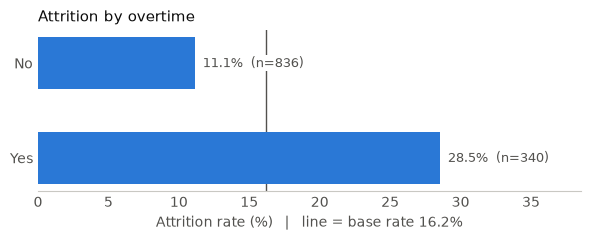

,mean,size
OverTime,,
No,0.111244,836
Yes,0.285294,340


In [2]:
table = train.groupby("OverTime")[TARGET].agg(["mean", "size"])
plot_rate_table(table, "Attrition by overtime", base_rate)
plt.show()
table

**Finding:** Employees who work overtime leave at 28.5% vs 11.1% for those who don't (n = 340 vs 836) — about 2.6× the rate. Overtime is associated with substantially higher attrition.

## 2. Categorical columns (your turn)

One cell per column: **BusinessTravel, Department, JobRole, JobLevel, StockOptionLevel, EducationField.**
Copy the worked example's pattern. Write a finding under each. Watch group sizes (JobRole has small groups).

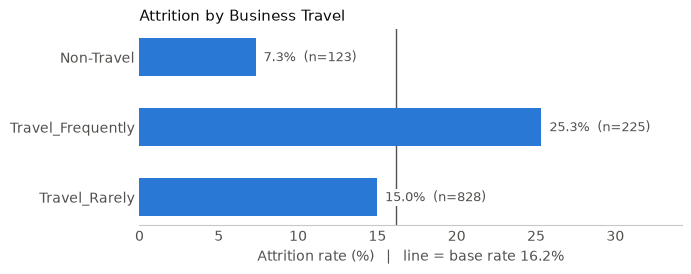

,mean,size
BusinessTravel,,
Non-Travel,0.073171,123
Travel_Frequently,0.253333,225
Travel_Rarely,0.149758,828


In [3]:
# BusinessTravel
table = train.groupby("BusinessTravel")[TARGET].agg(["mean", "size"])
plot_rate_table(table, "Attrition by Business Travel", base_rate)
plt.show()
table

Employees who tend to tarvel frequently have left(25.3%) cpmpared to employees who don't travel(7.3%) and who rarely travel(15%)

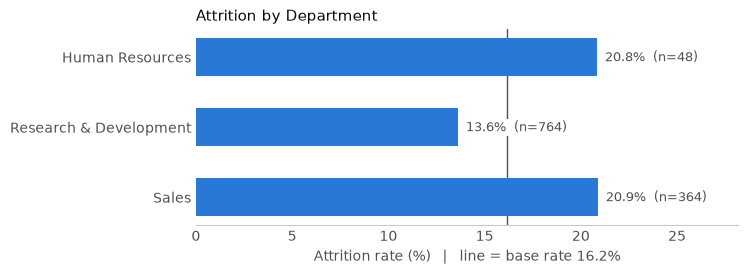

,mean,size
Department,,
Human Resources,0.208333,48
Research & Development,0.136126,764
Sales,0.208791,364


In [4]:
# Department
table = train.groupby("Department")[TARGET].agg(["mean", "size"])
plot_rate_table(table, "Attrition by Department", base_rate)
plt.show()
table

Employees who belong to Sales have left more(20.9%) with higher count(364) compared to other departments.

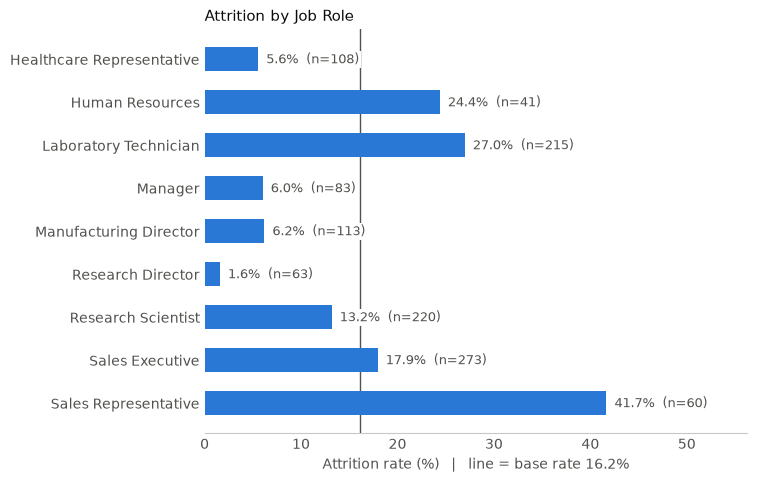

,mean,size
JobRole,,
Healthcare Representative,0.055556,108
Human Resources,0.243902,41
Laboratory Technician,0.269767,215
Manager,0.060241,83
Manufacturing Director,0.061947,113
Research Director,0.015873,63
Research Scientist,0.131818,220
Sales Executive,0.179487,273
Sales Representative,0.416667,60


In [7]:
# JobRole
table = train.groupby("JobRole")[TARGET].agg(["mean", "size"])
plot_rate_table(table, "Attrition by Job Role", base_rate)
plt.show()
table

Lab technicians(27%, count = 215) and people who belong to sales(sales executive and sales rep) have left more(17.9% and 41%) than other job people.

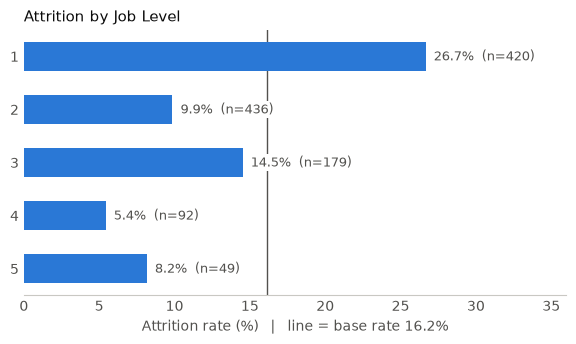

,mean,size
JobLevel,,
1,0.266667,420
2,0.098624,436
3,0.145251,179
4,0.054348,92
5,0.081633,49


In [8]:
# JobLevel
table = train.groupby("JobLevel")[TARGET].agg(["mean", "size"])
plot_rate_table(table, "Attrition by Job Level", base_rate)
plt.show()
table

Level 1 employees have left more(26.7%) with a count of 420 than other level people.

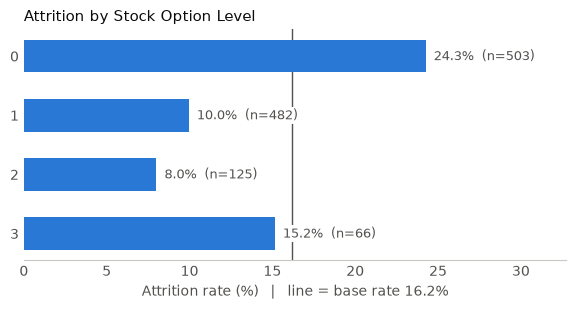

,mean,size
StockOptionLevel,,
0,0.242545,503
1,0.099585,482
2,0.080000,125
3,0.151515,66


In [9]:
# StockOptionLevel
table = train.groupby("StockOptionLevel")[TARGET].agg(["mean", "size"])
plot_rate_table(table, "Attrition by Stock Option Level", base_rate)
plt.show()
table

People who got no stocks have left more(24.3%) with a count of 503 than other level people.

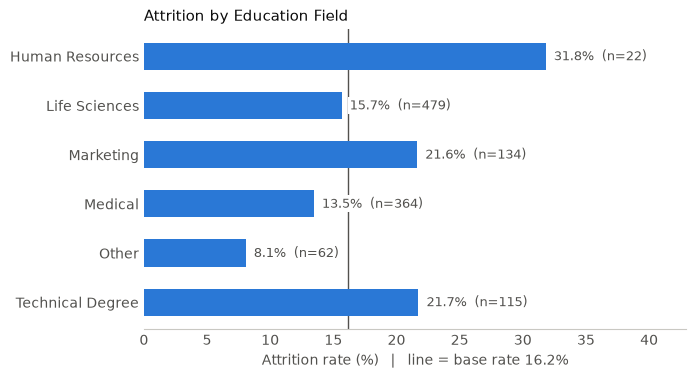

,mean,size
EducationField,,
Human Resources,0.318182,22
Life Sciences,0.156576,479
Marketing,0.216418,134
Medical,0.134615,364
Other,0.080645,62
Technical Degree,0.217391,115


In [10]:
# EducationField
table = train.groupby("EducationField")[TARGET].agg(["mean", "size"])
plot_rate_table(table, "Attrition by Education Field", base_rate)
plt.show()
table

Employees who did technical degree(21.7%) and marketing(21.6%) tend to leave more.

## 3. Numeric columns (your turn)

Use `pd.qcut(train[col], q=4)` to make equal-sized bands, then the same pattern.
Columns: **MonthlyIncome, YearsAtCompany, TotalWorkingYears, DistanceFromHome, NumCompaniesWorked.**

`qcut` fails if many people share the same value (e.g. lots of 0s). If you see `ValueError: Bin edges must be unique`, add `duplicates="drop"` and note that you got fewer than 4 bands.

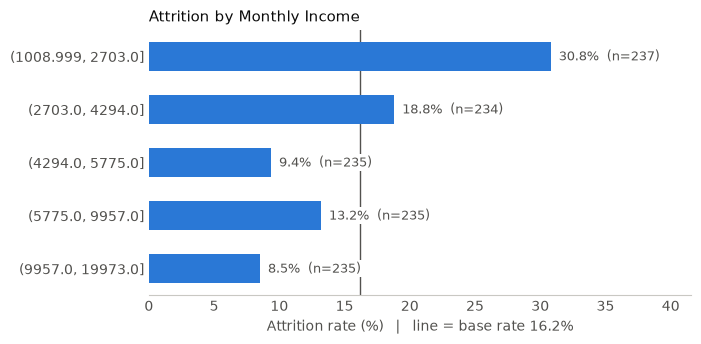

,mean,size
MonthlyIncome,,
"(1008.999, 2703.0]",0.308017,237
"(2703.0, 4294.0]",0.188034,234
"(4294.0, 5775.0]",0.093617,235
"(5775.0, 9957.0]",0.131915,235
"(9957.0, 19973.0]",0.085106,235


In [12]:
# MonthlyIncome
table = train.groupby(pd.qcut(train["MonthlyIncome"], q=5))[TARGET].agg(["mean", "size"])
plot_rate_table(table, "Attrition by Monthly Income", base_rate)
plt.show()
table

Employees who gets paid low(1008 to 2703) with 30.8% and (2703 to 4294) with 18.8% tend to leave more than other group employees.

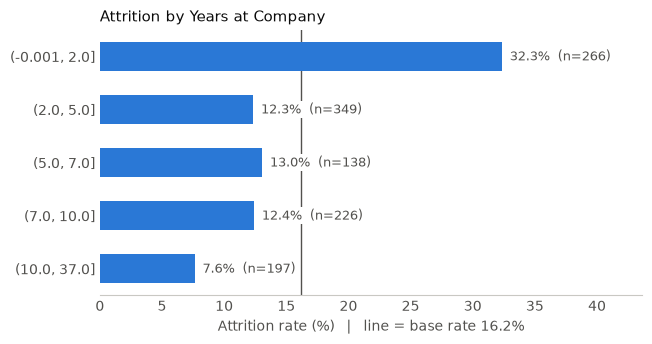

,mean,size
YearsAtCompany,,
"(-0.001, 2.0]",0.323308,266
"(2.0, 5.0]",0.123209,349
"(5.0, 7.0]",0.130435,138
"(7.0, 10.0]",0.123894,226
"(10.0, 37.0]",0.076142,197


In [26]:
# YearsAtCompany
table = train.groupby(pd.qcut(train["YearsAtCompany"], q=5))[TARGET].agg(["mean", "size"])
plot_rate_table(table, "Attrition by Years at Company", base_rate)
plt.show()
table

**Finding:** Employees with lesser years of service in the company tend to leave more(32.3%)

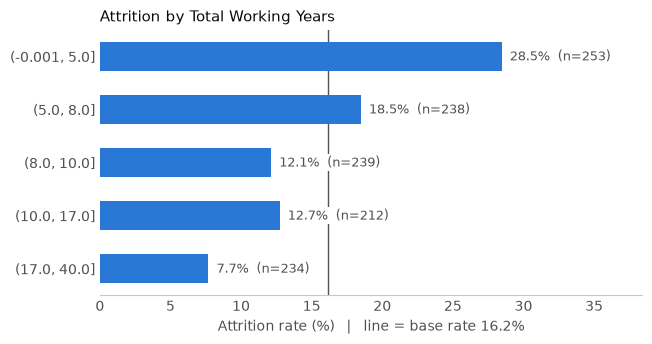

,mean,size
TotalWorkingYears,,
"(-0.001, 5.0]",0.284585,253
"(5.0, 8.0]",0.184874,238
"(8.0, 10.0]",0.121339,239
"(10.0, 17.0]",0.127358,212
"(17.0, 40.0]",0.076923,234


In [27]:
# TotalWorkingYears
table1 = train.groupby(pd.qcut(train["TotalWorkingYears"], q=5))[TARGET].agg(["mean", "size"])
plot_rate_table(table1, "Attrition by Total Working Years", base_rate)
plt.show()
table1

**Finding:** Early career employees with total experience less than five tend to leave more(28.5%)

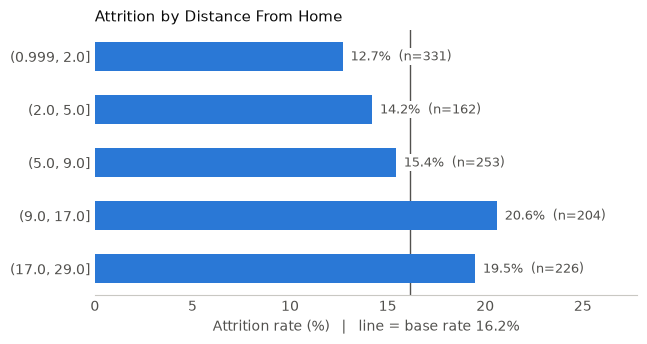

,mean,size
DistanceFromHome,,
"(0.999, 2.0]",0.126888,331
"(2.0, 5.0]",0.141975,162
"(5.0, 9.0]",0.154150,253
"(9.0, 17.0]",0.205882,204
"(17.0, 29.0]",0.194690,226


In [28]:
# DistanceFromHome
table2 = train.groupby(pd.qcut(train["DistanceFromHome"], q=5))[TARGET].agg(["mean", "size"])
plot_rate_table(table2, "Attrition by Distance From Home", base_rate)
plt.show()
table2

**Finding:** Employees who are far from the office tend to leave more than exployees who are nearer to the office, but it is not a substancial factor as it doesn't have huge difference.

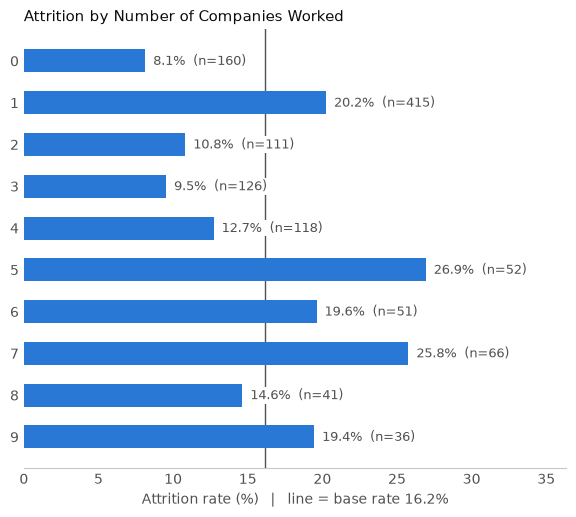

,mean,size
NumCompaniesWorked,,
0,0.081250,160
1,0.202410,415
2,0.108108,111
3,0.095238,126
4,0.127119,118
5,0.269231,52
6,0.196078,51
7,0.257576,66
8,0.146341,41


In [29]:
# NumCompaniesWorked without qcut
table3 = train.groupby("NumCompaniesWorked")[TARGET].agg(["mean", "size"])
plot_rate_table(table3, "Attrition by Number of Companies Worked", base_rate)
plt.show()
table3

**Finding:** Early career employees who worked in lesser companies in their career tend to leave more(20.2%) than employees who work 2 plus years, also employees with 5 plus years of experience tend to leave more(22%) than employees who stay more then for eight years(14.6%).

## 4. Survey columns — flagged `suspicious` (unknown timing)

**JobSatisfaction, EnvironmentSatisfaction, RelationshipSatisfaction, WorkLifeBalance, JobInvolvement.**
Same pattern. In each finding, remind the reader these may leak if collected at exit.

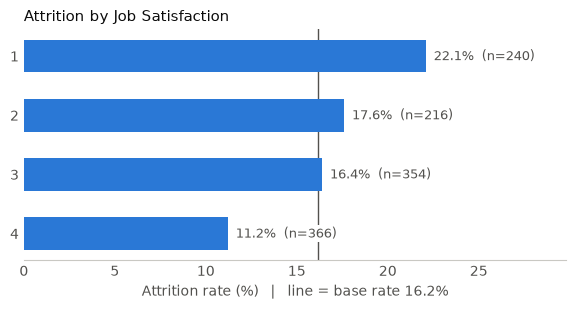

,mean,size
JobSatisfaction,,
1,0.220833,240
2,0.175926,216
3,0.163842,354
4,0.112022,366


In [31]:
# JobSatisfaction
table1 = train.groupby("JobSatisfaction")[TARGET].agg(["mean", "size"])
plot_rate_table(table1, "Attrition by Job Satisfaction", base_rate)
plt.show()
table1

**Finding:** This factor is suspicious as we don't know when it was recorded, employees with less satisfaction in the job left more(22.1%) 

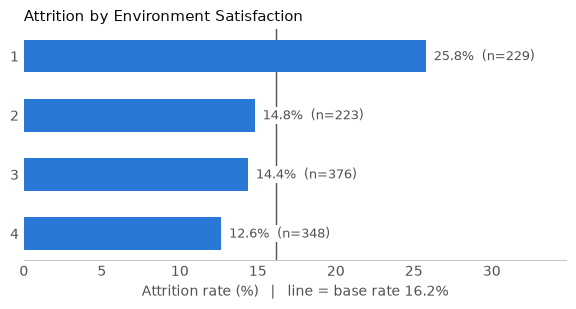

,mean,size
EnvironmentSatisfaction,,
1,0.257642,229
2,0.147982,223
3,0.143617,376
4,0.126437,348


In [32]:
# EnvironmentSatisfaction
table2 = train.groupby("EnvironmentSatisfaction")[TARGET].agg(["mean", "size"])
plot_rate_table(table2, "Attrition by Environment Satisfaction", base_rate)
plt.show()
table2

**Finding:** This factor is suspicious as we don't know when it was recorded, employees with less satisfaction in the environment left more(25.8%) 

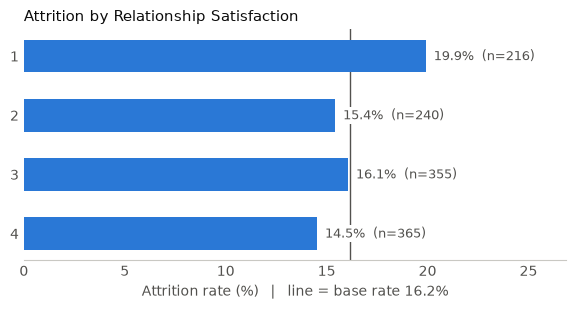

,mean,size
RelationshipSatisfaction,,
1,0.199074,216
2,0.154167,240
3,0.160563,355
4,0.145205,365


In [36]:
# RelationshipSatisfaction
table2 = train.groupby("RelationshipSatisfaction")[TARGET].agg(["mean", "size"])
plot_rate_table(table2, "Attrition by Relationship Satisfaction", base_rate)
plt.show()
table2

**Finding:** This factor is suspicious as we don't know when it was recorded, but there is no significant difference, so this can be ignored as a factor.

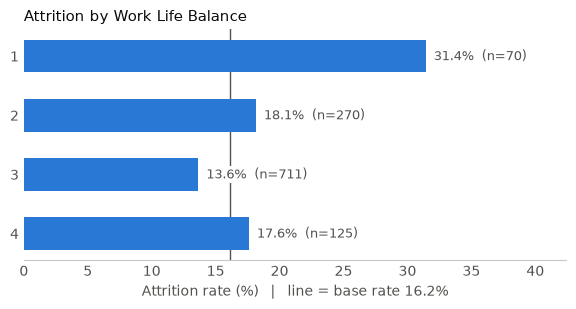

,mean,size
WorkLifeBalance,,
1,0.314286,70
2,0.181481,270
3,0.136428,711
4,0.176000,125


In [34]:
# WorkLifeBalance
table3 = train.groupby("WorkLifeBalance")[TARGET].agg(["mean", "size"])
plot_rate_table(table3, "Attrition by Work Life Balance", base_rate)
plt.show()
table3

**Finding:** This factor is suspicious as we don't know when it was recorded, employees with lesser work life balance left more(31.4%) 

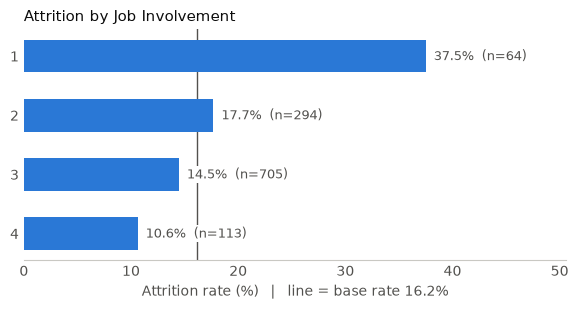

,mean,size
JobInvolvement,,
1,0.375000,64
2,0.176871,294
3,0.144681,705
4,0.106195,113


In [35]:
# JobInvolvement
table4 = train.groupby("JobInvolvement")[TARGET].agg(["mean", "size"])
plot_rate_table(table4, "Attrition by Job Involvement", base_rate)
plt.show()
table4

**Finding:** This factor is suspicious as we don't know when it was recorded, employees with lesser job involvement left more(37.5%) 

## 5. Protected attributes — described here, NOT model inputs

**Age (use qcut), Gender, MaritalStatus.** We describe them so the fairness checks in M5 have a baseline.

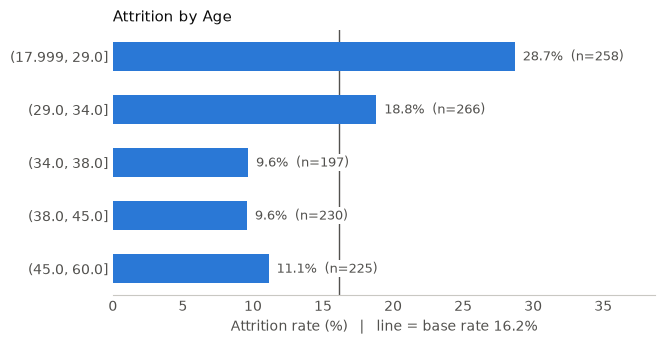

,mean,size
Age,,
"(17.999, 29.0]",0.286822,258
"(29.0, 34.0]",0.187970,266
"(34.0, 38.0]",0.096447,197
"(38.0, 45.0]",0.095652,230
"(45.0, 60.0]",0.111111,225


In [37]:
# Age
table = train.groupby(pd.qcut(train["Age"], q=5))[TARGET].agg(["mean", "size"])
plot_rate_table(table, "Attrition by Age", base_rate)
plt.show()
table

**Finding:** People who are young(28.7 % and 18.8%) have left more than older people, this are not concusion, these are calculated to check if the model is fairly treating.

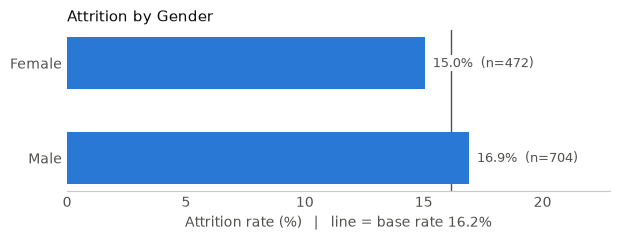

,mean,size
Gender,,
Female,0.150424,472
Male,0.169034,704


In [38]:
# Gender
table1 = train.groupby("Gender")[TARGET].agg(["mean", "size"])
plot_rate_table(table1, "Attrition by Gender", base_rate)
plt.show()
table1

**Finding:** Gender doesn't play a part as a factor here.

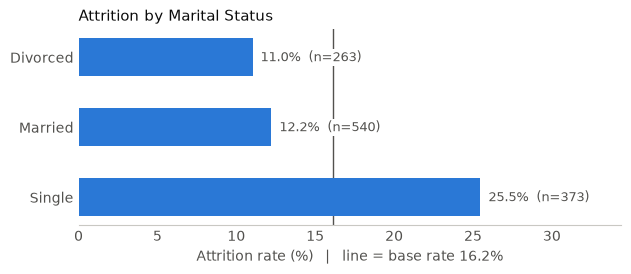

,mean,size
MaritalStatus,,
Divorced,0.110266,263
Married,0.122222,540
Single,0.254692,373


In [39]:
# MaritalStatus
table2 = train.groupby("MaritalStatus")[TARGET].agg(["mean", "size"])
plot_rate_table(table2, "Attrition by Marital Status", base_rate)
plt.show()
table2

**Finding:** People who are single(25.5%) tend to leave than divorced/married people, this are not concusion, these are calculated to check if the model is fairly treating.

## 6. Top 5 findings (write last)

Rank by strength *and* group size. One line each, in the finding format.

1. Employees who've worked overtime have left more(28.5%).
2. Employees who worked as laboratory technicians tend to leave more(27%).
3. Employees with lesser salary left more(30.8%).
4. Employees who travel frequently have left more(25.3%).
5. Employees at lower job level tend to leave more(26%).
6. EMployees with no stock option tend to leave more(24.3%)

## 7. Assumptions and limitations

- Fictional dataset; patterns may not transfer to a real company.
- Survey scores assumed collected before any resignation (unverifiable here).
- Tenure columns are frozen at exit for leavers but current for stayers.
- These are associations, not causes.